# 🧠 BrainScan – Beyin MR Görüntülerinde Tümör Sınıflandırması

Bu notebook, beyin MR görüntülerini **4 sınıfa** ayıran uçtan uca bir derin öğrenme projesidir:

| Sınıf | Açıklama |
|---|---|
| `glioma` | Glioma tümörü |
| `meningioma` | Meningioma tümörü |
| `pituitary` | Hipofiz (pituitary) tümörü |
| `notumor` | Tümör yok |

Projede iki model eğitilir ve **aynı test seti** üzerinde karşılaştırılır:

1. **Baseline CNN** – sıfırdan yazılmış, 4 bloklu basit bir evrişimli ağ
2. **EfficientNetB0** – ImageNet ile önceden eğitilmiş model (önce *transfer learning*, sonra *fine-tuning*)

Veri analizinden model karşılaştırmasına, hata analizinden Grad-CAM yorumlanabilirliğine ve yeni bir MR görüntüsüyle tahmine kadar tüm adımlar bu notebook içindedir.

> ⚠️ **Önemli uyarı:** Bu proje **yalnızca eğitim ve araştırma amaçlıdır.** Modeller klinik olarak doğrulanmamıştır; tıbbi teşhis, tedavi kararı veya hasta değerlendirmesi için **kullanılamaz.** Bu notebook'taki hiçbir sonuç bir doktorun değerlendirmesinin yerini tutmaz.

### 📑 İçindekiler

1. Proje başlığı ve açıklaması
2. Kütüphanelerin yüklenmesi
3. Ayarlar ve veri seti yolu
4. Veri setinin yüklenmesi
5. Keşifsel veri analizi (EDA) ve tekrar eden görüntü kontrolü
6. Veri görselleştirme
7. Veri ön işleme
8. Data Augmentation
9. Baseline CNN modeli
10. Baseline CNN eğitimi
11. EfficientNetB0 modeli
12. EfficientNetB0 eğitimi
13. Fine-Tuning
14. Eğitim grafiklerinin incelenmesi
15. Modellerin performans karşılaştırması
16. Confusion Matrix
17. Classification Report
18. ROC-AUC analizi
19. Yanlış tahminlerin incelenmesi
20. Grad-CAM görselleştirmesi
21. Yeni MR görüntüsü ile tahmin
22. Genel sonuç ve değerlendirme

### ▶️ Nasıl çalıştırılır?

- Hücreleri **yukarıdan aşağıya sırayla** çalıştır (`Kernel → Restart & Run All`).
- Eğitim süresi bilgisayarına bağlıdır. GPU yoksa EfficientNet eğitimi uzun sürebilir; **Google Colab** kullanabilirsin.
- Her şeyin hatasız çalıştığını önce hızlıca görmek istersen 3. bölümde `HIZLI_TEST = True` yap (küçük veri + 1 epoch). **O modda çıkan sonuçlar anlamsızdır**, sadece kod denemesi içindir.
- Bu notebook'taki **hiçbir sayı önceden yazılmamıştır**; tüm değerler hücreler çalıştırıldıkça senin bilgisayarında hesaplanır.

## 2. Kütüphanelerin yüklenmesi

Önce gerekli kütüphaneleri import ediyoruz. Eksik kütüphane varsa terminalde şu komutla kurabilirsin:

```bash
pip install tensorflow scikit-learn pandas matplotlib pillow
```

- `tensorflow` / `keras`: model kurma ve eğitme
- `scikit-learn`: metrikler (precision, recall, F1, ROC-AUC, confusion matrix) ve veri bölme
- `pandas`: tablolar
- `matplotlib`: grafikler
- `pillow`: görüntü okuma
- `tkinter`: yeni görüntü seçerken dosya penceresi açmak için (Python ile birlikte gelir)

In [1]:
import os, json, time, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, auc,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
gpu = tf.config.list_physical_devices("GPU")
print("GPU:", gpu if gpu else "bulunamadı (CPU ile eğitim yavaş olabilir)")

TensorFlow: 2.22.0-rc0 | Keras: 3.16.0.dev2026101104
GPU: bulunamadı (CPU ile eğitim yavaş olabilir)


## 3. Ayarlar ve veri seti yolu

Tüm ayarları tek yerde topluyoruz; bir şeyi değiştirmek istediğinde sadece bu hücreyi düzenlemen yeterli.

- `DATA_DIR`: veri seti klasörü (içinde `Training/` ve `Testing/` olmalı). Projedeki mevcut yol korunmuştur.
- `TEKRARLARI_CIKAR`: Eğitim setinde, test setindeki bir görüntüyle **aynı olan** veya eğitim içinde **tekrar eden** görüntüler çıkarılsın mı? (Veri sızıntısını önlemek için `True` önerilir.)
- `ONCEDEN_EGITILMIS`: `True` ise EfficientNetB0 ImageNet ağırlıklarıyla başlar (ilk çalıştırmada internet gerekir).
- `HIZLI_TEST`: Sadece kodu denemek için küçük veri ve 1 epoch kullanır.

In [2]:
# --- Veri seti yolu ---
DATA_DIR = os.path.abspath("data") if os.path.isdir("data") else (
    os.path.abspath(os.path.join("..", "data")) if os.path.isdir(os.path.join("..", "data")) else r"C:\Users\berat\Desktop\tümör\data"
)

# --- Eğitim ayarları ---
IMG_SIZE = 224            # görüntüler 224x224'e getirilir
BATCH_SIZE = 32
EPOCHS = 15               # baseline ve EfficientNet (1. aşama) için en fazla epoch
FINETUNE_EPOCHS = 10      # fine-tuning için en fazla epoch (en az 1 olmalı)
FINETUNE_LAYERS = 30      # fine-tuning'de eğitime açılacak son katman sayısı
VAL_ORANI = 0.2           # eğitim verisinin %20'si doğrulama (validation) için ayrılır
SEED = 42                 # sonuçların tekrarlanabilir olması için

# --- Seçenekler ---
TEKRARLARI_CIKAR = True       # tekrar eden eğitim görüntülerini çıkar (veri sızıntısı önlemi)
ONCEDEN_EGITILMIS = True      # EfficientNetB0 için ImageNet ağırlıkları
HIZLI_TEST = False            # True: küçük veri + 1 epoch (sadece kod denemesi için!)

if HIZLI_TEST:
    EPOCHS, FINETUNE_EPOCHS = 1, 1

# --- Çıktı klasörleri ---
OUTPUT_DIR = "outputs"
MODEL_DIR = os.path.join(OUTPUT_DIR, "models")      # .keras model dosyaları
FIG_DIR = os.path.join(OUTPUT_DIR, "figures")       # grafikler
REPORT_DIR = os.path.join(OUTPUT_DIR, "reports")    # CSV ve metin raporları
for klasor in (MODEL_DIR, FIG_DIR, REPORT_DIR):
    os.makedirs(klasor, exist_ok=True)

# Model adı -> dosya adı eşlemesi (tüm kayıtlarda aynı adlar kullanılır)
MODEL_ADLARI = {
    "Baseline CNN": "baseline_cnn",
    "EfficientNetB0 (Transfer)": "efficientnet_b0_transfer",
    "EfficientNetB0 (Fine-Tuned)": "efficientnet_b0_finetuned",
}

def model_yolu(ad):
    """Model adından .keras dosya yolunu üretir."""
    return os.path.join(MODEL_DIR, MODEL_ADLARI[ad] + ".keras")

def grafik_kaydet(fig, dosya_adi):
    """Grafiği outputs/figures klasörüne kaydeder."""
    fig.savefig(os.path.join(FIG_DIR, dosya_adi), dpi=150, bbox_inches="tight")

keras.utils.set_random_seed(SEED)   # numpy, python ve tensorflow tohumlarını sabitler
print("Ayarlar hazır. Çıktılar şu klasöre yazılacak:", os.path.abspath(OUTPUT_DIR))
print("Kullanılan veri seti yolu:", DATA_DIR)

Ayarlar hazır. Çıktılar şu klasöre yazılacak: C:\Users\berat\Desktop\brainscan\notebooks\outputs
Kullanılan veri seti yolu: C:\Users\berat\Desktop\brainscan\data


## 4. Veri setinin yüklenmesi

Önce klasörleri tarayıp her görüntünün **yolunu, sınıfını ve hangi bölümde (Training/Testing) olduğunu** bir pandas tablosuna (`df`) yazıyoruz. Görüntülerin kendisini henüz belleğe almıyoruz.

Bu yaklaşımın faydaları:
- Sınıf sayılarını ve tekrar eden görüntüleri kolayca analiz edebiliriz.
- Yanlış tahmin edilen görüntülerin dosya yolunu sonradan bulabiliriz.
- Sınıf sırası klasör adlarının alfabetik sırasıdır ve **tüm modellerde aynı** kullanılır.

In [3]:
egitim_klasoru = os.path.join(DATA_DIR, "Training")
test_klasoru = os.path.join(DATA_DIR, "Testing")
if not (os.path.isdir(egitim_klasoru) and os.path.isdir(test_klasoru)):
    raise FileNotFoundError(f"'{DATA_DIR}' içinde Training ve Testing klasörleri bulunamadı. "
                            "3. bölümdeki DATA_DIR yolunu kontrol et.")

# Sınıf adları klasör adlarından alınır, alfabetik sıralanır (tüm modellerde aynı sıra)
sinif_adlari = sorted(k for k in os.listdir(egitim_klasoru)
                      if os.path.isdir(os.path.join(egitim_klasoru, k)))
sinif_id = {ad: i for i, ad in enumerate(sinif_adlari)}
print("Sınıflar:", sinif_adlari)

# Her görüntü için bir satır: yol, sınıf, bölüm
kayitlar = []
for bolum in ["Training", "Testing"]:
    for sinif in sinif_adlari:
        klasor = os.path.join(DATA_DIR, bolum, sinif)
        for dosya in sorted(os.listdir(klasor)):
            if dosya.lower().endswith((".jpg", ".jpeg", ".png")):
                kayitlar.append({"yol": os.path.join(klasor, dosya), "sinif": sinif, "bolum": bolum})
df = pd.DataFrame(kayitlar)

if HIZLI_TEST:   # sadece kodu denemek için her bölüm/sınıftan az sayıda görüntü al
    df = df.groupby(["bolum", "sinif"]).head(60).reset_index(drop=True)
    print("⚠️ HIZLI_TEST açık: veri seti küçültüldü, sonuçlar anlamlı DEĞİLDİR!")

print("Toplam görüntü sayısı:", len(df))
df.head()

Sınıflar: ['glioma', 'meningioma', 'notumor', 'pituitary']
Toplam görüntü sayısı: 7200


,yol,sinif,bolum
0,C:\Users\berat\Desktop\brainscan\data\Training...,glioma,Training
1,C:\Users\berat\Desktop\brainscan\data\Training...,glioma,Training
2,C:\Users\berat\Desktop\brainscan\data\Training...,glioma,Training
3,C:\Users\berat\Desktop\brainscan\data\Training...,glioma,Training
4,C:\Users\berat\Desktop\brainscan\data\Training...,glioma,Training


## 5. Keşifsel veri analizi (EDA)

Modeli eğitmeden önce veriyi tanımalıyız. Bu bölümde üç şeye bakıyoruz:

1. **Sınıf dağılımı:** Her sınıftan kaç görüntü var? Sınıflar dengeli mi?
2. **Görüntü özellikleri:** Çözünürlükler ve renk modları aynı mı?
3. **Tekrar eden görüntüler:** Aynı MR görüntüsü hem eğitimde hem testte varsa model testte "ezberlediği" görüntüyü tanır ve başarı **olduğundan yüksek** görünür. Buna **veri sızıntısı (data leakage)** denir.

In [4]:
# 1) Sınıf başına görüntü sayıları
sayim = df.groupby(["sinif", "bolum"]).size().unstack("bolum")[["Training", "Testing"]]
sayim["Training %"] = (sayim["Training"] / sayim["Training"].sum() * 100).round(1)
sayim["Testing %"] = (sayim["Testing"] / sayim["Testing"].sum() * 100).round(1)
display(sayim)
print("Toplam -> Training:", sayim["Training"].sum(), "| Testing:", sayim["Testing"].sum())

# Dengesizlik oranı: en kalabalık sınıf / en az görüntülü sınıf (1'e yakınsa dengeli)
for bolum in ["Training", "Testing"]:
    s = sayim[bolum]
    print(f"{bolum}: dengesizlik oranı = {s.max() / s.min():.2f}  "
          f"(en çok: {s.idxmax()} = {s.max()}, en az: {s.idxmin()} = {s.min()})")

bolum,Training,Testing,Training %,Testing %
sinif,,,,
glioma,1400,400,25.0,25.0
meningioma,1400,400,25.0,25.0
notumor,1400,400,25.0,25.0
pituitary,1400,400,25.0,25.0


Toplam -> Training: 5600 | Testing: 1600
Training: dengesizlik oranı = 1.00  (en çok: glioma = 1400, en az: glioma = 1400)
Testing: dengesizlik oranı = 1.00  (en çok: glioma = 400, en az: glioma = 400)


**📝 Yorum (nasıl okunur?):** Dengesizlik oranı **1.00'a yakınsa** sınıflar dengelidir ve accuracy güvenilir bir ölçüdür. Oran büyüdükçe model çok görüntülü sınıfa yönelir; bu durumda accuracy yanıltıcı olabilir ve **macro F1 / recall** gibi sınıf bazlı metriklere daha çok bakmak gerekir. Bu notebook, eğitim verisinde oran **1.5'ten büyükse** otomatik olarak `class_weight` kullanır (7. bölüm).

In [5]:
# 2) Görüntü çözünürlüğü ve renk modu (dosyanın sadece başlığı okunur, hızlıdır)
bilgiler = []
for yol in df["yol"]:
    with Image.open(yol) as im:
        bilgiler.append((im.size[0], im.size[1], im.mode))
df[["genislik", "yukseklik", "mod"]] = pd.DataFrame(bilgiler, index=df.index)

cozunurluk = (df["genislik"].astype(str) + "x" + df["yukseklik"].astype(str)).value_counts()
print("Farklı çözünürlük sayısı:", len(cozunurluk))
display(cozunurluk.head(5).to_frame("Görüntü sayısı"))
print("Renk modları:", df["mod"].value_counts().to_dict())

Farklı çözünürlük sayısı: 447


,Görüntü sayısı
512x512,5014
225x225,338
630x630,90
201x251,57
228x221,51


Renk modları: {'RGB': 4129, 'L': 3067, 'RGBA': 3, 'P': 1}


**📝 Yorum:** Görüntüler farklı çözünürlüklerde olabilir; modeller sabit boyutlu girdi beklediği için hepsini 7. bölümde **224x224**'e getireceğiz. Bazı görüntüler gri tonlamalı (`L`), bazıları `RGB` olabilir; EfficientNetB0 3 kanal beklediği için hepsini 3 kanala çevireceğiz.

### Tekrar eden görüntü kontrolü

İki yöntem kullanıyoruz:
- **MD5:** Dosyaların baytları birebir aynı mı? (Sadece tam kopyaları yakalar.)
- **Görsel hash:** Görüntüyü 17x16 gri tona küçültüp komşu piksellerin parlaklık karşılaştırmasından bir "parmak izi" çıkarır. Aynı görüntü farklı boyutta/sıkıştırmada kaydedilmiş olsa bile **görsel olarak aynı** olanları yakalar.

In [6]:
def dosya_md5(yol):
    """Dosyanın baytlarından MD5 parmak izi üretir."""
    with open(yol, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

def gorsel_hash(yol, n=16):
    """Görüntüyü (n+1)xn gri tona küçültür; komşu piksellerin karşılaştırmasından bit dizisi üretir."""
    with Image.open(yol) as im:
        k = np.asarray(im.convert("L").resize((n + 1, n), Image.LANCZOS), dtype=np.int16)
    return "".join("1" if x else "0" for x in (k[:, 1:] > k[:, :-1]).flatten())

df["md5"] = df["yol"].map(dosya_md5)
df["gorsel"] = df["yol"].map(gorsel_hash)

egitim = df[df["bolum"] == "Training"]
test = df[df["bolum"] == "Testing"]

tekrar_tablosu = pd.DataFrame({
    "Birebir aynı dosya (MD5)": [
        int(egitim["md5"].duplicated().sum()),
        int(test["md5"].duplicated().sum()),
        int(test["md5"].isin(egitim["md5"]).sum())],
    "Görsel olarak aynı (hash)": [
        int(egitim["gorsel"].duplicated().sum()),
        int(test["gorsel"].duplicated().sum()),
        int(test["gorsel"].isin(egitim["gorsel"]).sum())],
}, index=["Eğitim içinde fazladan kopya", "Test içinde fazladan kopya",
          "Eğitimde de bulunan test görüntüsü (SIZINTI)"])
display(tekrar_tablosu)

# Aynı görüntü farklı sınıf etiketi taşıyorsa etiket hatası olabilir
celiski = int((df.groupby("gorsel")["sinif"].nunique() > 1).sum())
print("Aynı görsel parmak izine sahip ama farklı sınıfa etiketlenmiş grup sayısı:", celiski)

,Birebir aynı dosya (MD5),Görsel olarak aynı (hash)
Eğitim içinde fazladan kopya,171,250
Test içinde fazladan kopya,16,33
Eğitimde de bulunan test görüntüsü (SIZINTI),0,160


Aynı görsel parmak izine sahip ama farklı sınıfa etiketlenmiş grup sayısı: 0


**📝 Yorum:** Tablodaki en önemli satır **"Eğitimde de bulunan test görüntüsü"** satırıdır. Bu değer **0'dan büyükse** test setindeki bazı görüntülerin eğitimde de bulunduğu anlamına gelir ve test başarısı gerçekte olduğundan iyimser çıkar. `TEKRARLARI_CIKAR = True` iken 7. bölümde bu görüntüler **eğitim setinden çıkarılır** (test seti olduğu gibi bırakılır). Eğitim içindeki fazladan kopyalar da çıkarılır; böylece aynı görüntü hem eğitim hem doğrulama kümesine düşüp doğrulama başarısını şişirmez.

> ℹ️ Bu kontrol aynı görüntünün kopyalarını bulur. **Aynı hastanın farklı kesitleri** (birbirine benzeyen ama aynı olmayan görüntüler) bu yöntemle bulunamaz; veri setinde hasta kimliği olmadığı için bu bir sınırlamadır (22. bölüme bak).

## 6. Veri görselleştirme

Önce sınıf dağılımını (çubuk + pasta grafik), sonra her sınıftan rastgele örnek MR görüntülerini çiziyoruz.

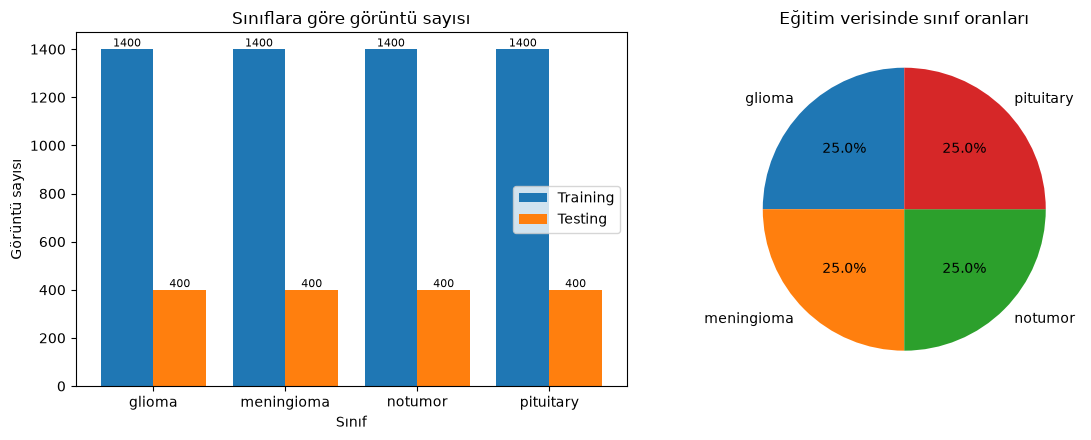

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Sol: Training ve Testing için sınıf başına görüntü sayısı
x = np.arange(len(sinif_adlari))
kap1 = ax[0].bar(x - 0.2, sayim.loc[sinif_adlari, "Training"], 0.4, label="Training")
kap2 = ax[0].bar(x + 0.2, sayim.loc[sinif_adlari, "Testing"], 0.4, label="Testing")
ax[0].bar_label(kap1, fontsize=8)
ax[0].bar_label(kap2, fontsize=8)
ax[0].set_xticks(x)
ax[0].set_xticklabels(sinif_adlari)
ax[0].set_xlabel("Sınıf")
ax[0].set_ylabel("Görüntü sayısı")
ax[0].set_title("Sınıflara göre görüntü sayısı")
ax[0].legend()

# Sağ: Eğitim verisinde sınıfların yüzdesi
ax[1].pie(sayim.loc[sinif_adlari, "Training"], labels=sinif_adlari, autopct="%1.1f%%", startangle=90)
ax[1].set_title("Eğitim verisinde sınıf oranları")

plt.tight_layout()
grafik_kaydet(fig, "sinif_dagilimi.png")
plt.show()

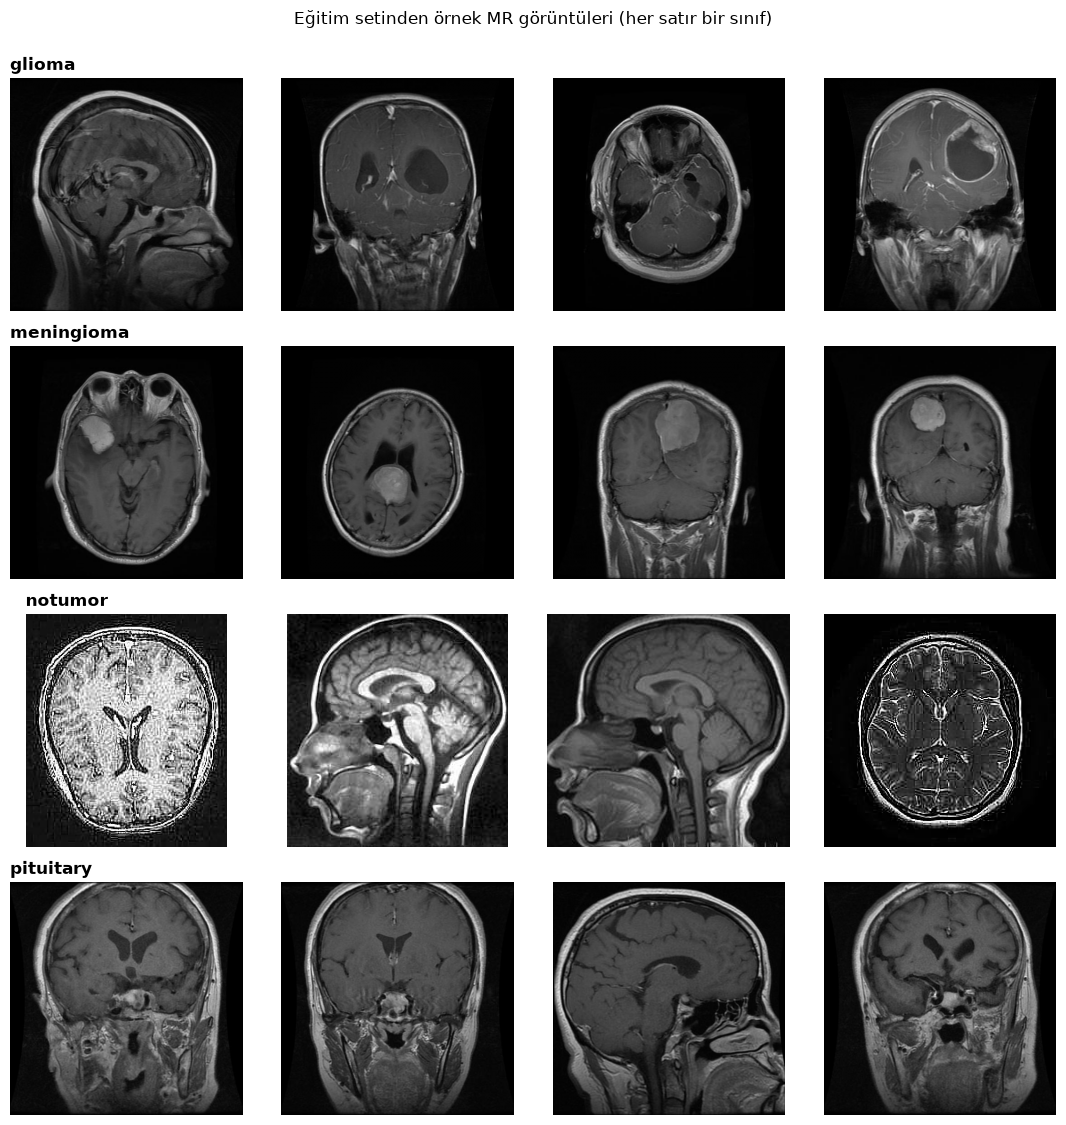

In [8]:
# Her sınıftan 4 rastgele örnek MR görüntüsü
fig, axes = plt.subplots(len(sinif_adlari), 4, figsize=(11, 2.8 * len(sinif_adlari)))
for i, sinif in enumerate(sinif_adlari):
    secim = df[(df["bolum"] == "Training") & (df["sinif"] == sinif)].sample(4, random_state=SEED)
    for j, yol in enumerate(secim["yol"]):
        axes[i, j].imshow(Image.open(yol), cmap="gray")
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(sinif, loc="left", fontsize=12, fontweight="bold")
fig.suptitle("Eğitim setinden örnek MR görüntüleri (her satır bir sınıf)", y=1.0)
plt.tight_layout()
grafik_kaydet(fig, "ornek_goruntuler.png")
plt.show()

**📝 Yorum:** Örnek görüntülerde kesit yönü (üstten, yandan, önden), kontrast ve kafatasının görüntüdeki yeri değişebilir. Sınıflar arasındaki farklar bazen gözle zor ayırt edilir; bu yüzden modelin neye baktığını Grad-CAM ile (20. bölüm) kontrol edeceğiz.

## 7. Veri ön işleme

Bu bölümde sırasıyla şunları yapıyoruz:

1. **Tekrarları çıkar** (`TEKRARLARI_CIKAR = True` ise): test ile aynı görünen ve kendi içinde tekrar eden eğitim görüntüleri atılır. Bu işlem **bölmeden önce** yapılır; böylece aynı görüntü hem eğitim hem doğrulamaya düşemez.
2. **Eğitim / doğrulama ayır:** Eğitim verisinin %20'si doğrulama için ayrılır (sınıf oranları korunarak). **Test seti eğitimde ve hiperparametre/epoch seçiminde kullanılmaz;** sadece en sonda değerlendirme için kullanılır.
3. **Sınıf ağırlığı:** Dengesizlik büyükse hesaplanır.
4. **tf.data hattı:** Görüntüler okunur, 3 kanala çevrilir ve 224x224'e getirilir.

**EfficientNetB0 ön işlemi:** Keras'ın `EfficientNetB0` modeli normalizasyonu **kendi içinde** yapar ve girdiyi **0–255** aralığında bekler. Bu yüzden görüntüleri 255'e **bölmüyoruz** (bölersek ön işlem iki kez uygulanmış olur). Baseline CNN kendi içinde `Rescaling(1/255)` kullanır.

In [9]:
egitim_df = df[df["bolum"] == "Training"].copy()
test_df = df[df["bolum"] == "Testing"].reset_index(drop=True)

# 1) Tekrar eden görüntüleri çıkar (sadece eğitim setinden; test seti değişmez)
onceki_sayi = len(egitim_df)
if TEKRARLARI_CIKAR:
    egitim_df = egitim_df[~egitim_df["gorsel"].isin(test_df["gorsel"])]   # test ile aynı görünenler
    egitim_df = egitim_df.drop_duplicates("gorsel")                       # kendi içinde tekrar edenler (ilki kalır)
print(f"Eğitim görüntüsü: {onceki_sayi} -> {len(egitim_df)}  (çıkarılan: {onceki_sayi - len(egitim_df)})")

# 2) Eğitim / doğrulama ayrımı (sınıf oranları korunur)
egitim_df, dogr_df = train_test_split(egitim_df, test_size=VAL_ORANI,
                                      stratify=egitim_df["sinif"], random_state=SEED)
egitim_df = egitim_df.reset_index(drop=True)
dogr_df = dogr_df.reset_index(drop=True)

bolme_tablosu = pd.DataFrame({
    "Eğitim": egitim_df["sinif"].value_counts(),
    "Doğrulama": dogr_df["sinif"].value_counts(),
    "Test": test_df["sinif"].value_counts(),
}).loc[sinif_adlari]
display(bolme_tablosu)
print("Toplam -> Eğitim:", len(egitim_df), "| Doğrulama:", len(dogr_df), "| Test:", len(test_df))

# 3) Sınıf ağırlığı: sadece dengesizlik oranı 1.5'ten büyükse kullanılır
sayilar = egitim_df["sinif"].value_counts()
dengesizlik = sayilar.max() / sayilar.min()
if dengesizlik > 1.5:
    agirliklar = compute_class_weight("balanced", classes=np.arange(len(sinif_adlari)),
                                      y=egitim_df["sinif"].map(sinif_id).values)
    sinif_agirliklari = {i: float(w) for i, w in enumerate(agirliklar)}
else:
    sinif_agirliklari = None
print(f"Eğitim dengesizlik oranı: {dengesizlik:.2f} -> class_weight:", sinif_agirliklari)

Eğitim görüntüsü: 5600 -> 5195  (çıkarılan: 405)


,Eğitim,Doğrulama,Test
sinif,,,
glioma,1117,279,400
meningioma,1030,257,400
notumor,923,231,400
pituitary,1086,272,400


Toplam -> Eğitim: 4156 | Doğrulama: 1039 | Test: 1600
Eğitim dengesizlik oranı: 1.21 -> class_weight: None


In [10]:
def goruntu_yukle(yol):
    """Dosyayı okur, 3 kanala çevirir ve IMG_SIZE x IMG_SIZE'a getirir (değerler 0-255 aralığında kalır)."""
    veri = tf.io.read_file(yol)
    goruntu = tf.image.decode_image(veri, channels=3, expand_animations=False)
    return tf.image.resize(goruntu, (IMG_SIZE, IMG_SIZE))

def dataset_olustur(tablo, karistir):
    """Tablodaki yollardan ve etiketlerden tf.data veri hattı oluşturur."""
    yollar = tablo["yol"].tolist()
    etiketler = tablo["sinif"].map(sinif_id).values.astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((yollar, etiketler))
    if karistir:
        ds = ds.shuffle(len(tablo), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda y, e: (goruntu_yukle(y), e), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

egitim_ds = dataset_olustur(egitim_df, karistir=True)
dogr_ds = dataset_olustur(dogr_df, karistir=False)
test_ds = dataset_olustur(test_df, karistir=False)   # sıra sabit: tahminler test_df ile eşleşir

# Kontrol: bir batch'in şekli ve değer aralığı
for x_batch, y_batch in egitim_ds.take(1):
    print("Batch şekli:", x_batch.shape, "| etiket şekli:", y_batch.shape)
    print("Piksel aralığı:", float(tf.reduce_min(x_batch)), "-", float(tf.reduce_max(x_batch)),
          "(0-255 olmalı; EfficientNet bunu bekler)")

# Sınıf adlarını ve ön işleme bilgisini modellerle birlikte kaydet
model_bilgisi = {
    "class_names": sinif_adlari,
    "img_size": IMG_SIZE,
    "on_isleme": "0-255 aralığında RGB girdi; Rescaling/normalizasyon model içinde yapılır",
    "seed": SEED,
}
with open(os.path.join(MODEL_DIR, "model_bilgisi.json"), "w", encoding="utf-8") as f:
    json.dump(model_bilgisi, f, ensure_ascii=False, indent=2)
print("Sınıf sırası (tüm modellerde aynı):", sinif_adlari)

Batch şekli: (32, 224, 224, 3) | etiket şekli: (32,)
Piksel aralığı: 0.0 - 255.0 (0-255 olmalı; EfficientNet bunu bekler)
Sınıf sırası (tüm modellerde aynı): ['glioma', 'meningioma', 'notumor', 'pituitary']


**📝 Yorum:** Yukarıdaki tablo, tekrarlar çıkarıldıktan sonraki **gerçek eğitim/doğrulama/test boyutlarını** gösterir. Piksel aralığının 0–255 olması, EfficientNetB0 için doğru ön işleme yapıldığını doğrular. Sınıf adları `model_bilgisi.json` dosyasına kaydedildi; böylece model daha sonra yüklendiğinde sınıf sırası karışmaz.

## 8. Data Augmentation

Eğitim görüntülerini her epoch'ta hafifçe değiştirerek modelin **ezberlemesini azaltmayı** amaçlıyoruz. Bu katmanlar **sadece eğitim sırasında** çalışır; doğrulama, test ve yeni görüntü tahmininde çalışmaz.

- **Baseline CNN:** Rotation (döndürme) ve zoom gibi uzamsal bozulmalar, BatchNormalization katmanları ile birleştiğinde doğrulama başarısında kararsızlığa (val_accuracy dalgalanması) yol açtığından, baseline modelde stabilite için yalnızca **yatay çevirme (`RandomFlip("horizontal")`)** kullanılır.
- **EfficientNetB0:** Taban model derin bir mimariye sahip olduğu ve transfer learning sırasında BatchNorm istatistikleri çıkarım modunda tutulduğu için tam veri çoğaltma (yatay çevirme, hafif döndürme, yakınlaştırma ve kontrast) uygulanır.

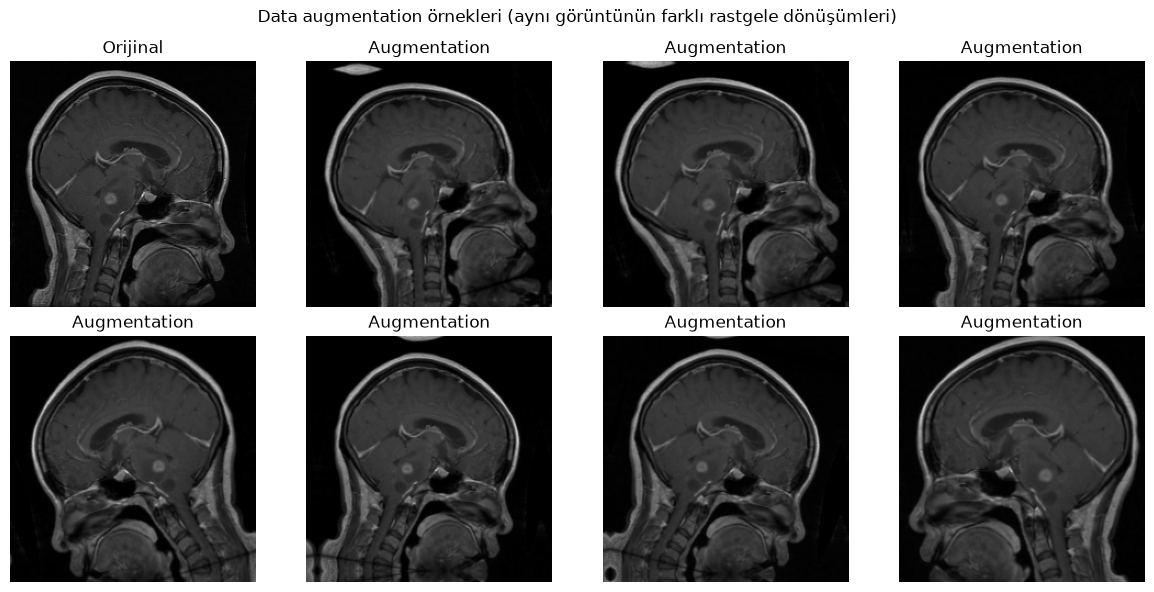

In [11]:
def augmentation_baseline():
    """Baseline CNN için sadece yatay çevirme (BatchNorm stabilitesi için)."""
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
    ], name="augment_baseline")

def augmentation_efficientnet():
    """EfficientNet için tam veri çoğaltma katmanları."""
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1),
    ], name="augment_efficientnet")

# Genel fonksiyon (EfficientNet ile eşleşir)
augmentation_olustur = augmentation_efficientnet

# Bir görüntünün orijinali ve 7 farklı augmentation sonucu
ornek = goruntu_yukle(egitim_df["yol"].iloc[0]).numpy()
aug = augmentation_efficientnet()

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes[0, 0].imshow(ornek.astype("uint8"))
axes[0, 0].set_title("Orijinal")
for ax in axes.flat[1:]:
    degismis = aug(ornek[None], training=True)[0].numpy()
    ax.imshow(np.clip(degismis, 0, 255).astype("uint8"))
    ax.set_title("Augmentation")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Data augmentation örnekleri (aynı görüntünün farklı rastgele dönüşümleri)")
plt.tight_layout()
grafik_kaydet(fig, "augmentation_ornekleri.png")
plt.show()

**📝 Yorum:** Her çalıştırmada farklı rastgele dönüşümler üretilir. Dönüşümler anatomiyi bozmayacak kadar küçüktür; amaç modelin görüntünün konumu veya kontrastı hafifçe değişse bile aynı sınıfı tanımasını sağlamaktır.

## 9. Baseline CNN modeli

Karşılaştırma için referans noktası olacak **basit bir CNN** kuruyoruz (`main.py`'deki mimari korunmuştur):

- 4 blok: `Conv2D → BatchNormalization(momentum=0.9) → MaxPooling`  (filtre sayıları 32, 64, 128, 256)
- `GlobalAveragePooling2D` ile özellikleri tek vektöre indirme
- `Dropout(0.4)` ile aşırı öğrenmeyi azaltma
- 4 nöronlu `softmax` çıkış (her sınıf için olasılık)

Girdi önce hafif augmentation'dan (yalnızca yatay çevirme) geçer, sonra `Rescaling(1/255)` ile 0–1 aralığına getirilir.

In [12]:
def build_baseline(sinif_sayisi):
    girdi = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augmentation_baseline()(girdi)
    x = layers.Rescaling(1.0 / 255)(x)                 # 0-255 -> 0-1
    for filtre in (32, 64, 128, 256):
        x = layers.Conv2D(filtre, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization(momentum=0.9)(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    cikis = layers.Dense(sinif_sayisi, activation="softmax")(x)
    return keras.Model(girdi, cikis, name="baseline_cnn")

baseline_model = build_baseline(len(sinif_adlari))
baseline_model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ augment_baseline (Sequential)        │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 224, 224, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 112, 112, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 56, 56, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 28, 28, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 28, 28, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 4)                   │           1,028 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 391,364 (1.49 MB)

 Trainable params: 390,404 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)

## 10. Baseline CNN eğitimi

Önce her iki modelde ortak kullanacağımız üç küçük fonksiyonu yazıyoruz:

- `derle`: Adam optimizer ve `sparse_categorical_crossentropy` kaybıyla modeli derler.
- `callbackler`: 
  - **EarlyStopping:** doğrulama kaybı 5 epoch iyileşmezse eğitimi durdurur.
  - **ReduceLROnPlateau:** doğrulama kaybı 2 epoch iyileşmezse öğrenme oranını düşürür.
  - **ModelCheckpoint:** en iyi doğrulama kaybına sahip modeli `.keras` dosyası olarak kaydeder.
- `egit`: Modeli eğitir, **süreyi ölçer** ve en iyi kaydedilmiş modeli geri yükler.

Model seçimi (en iyi epoch) **doğrulama** kaybına göre yapılır; test seti kullanılmaz.

In [13]:
def derle(model, ogrenme_orani):
    model.compile(optimizer=keras.optimizers.Adam(ogrenme_orani),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

def callbackler(kayit_yolu):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2),
        keras.callbacks.ModelCheckpoint(kayit_yolu, monitor="val_loss", save_best_only=True),
    ]

def egit(model, kayit_yolu, epochs):
    """Modeli eğitir; (en iyi model, history sözlüğü, süre[sn]) döndürür."""
    baslangic = time.perf_counter()
    gecmis = model.fit(egitim_ds, validation_data=dogr_ds, epochs=epochs,
                       class_weight=sinif_agirliklari,
                       callbacks=callbackler(kayit_yolu), verbose=2)
    sure = time.perf_counter() - baslangic
    en_iyi_model = keras.models.load_model(kayit_yolu)   # doğrulama kaybı en düşük olan model
    return en_iyi_model, gecmis.history, sure

gecmisler = {}   # model adı -> history listesi (grafikler için)
sureler = {}     # model adı -> eğitim süresi (saniye)

In [ ]:
# Baseline CNN eğitimi (öğrenme oranı 3e-4, Adam)
derle(baseline_model, 3e-4)
baseline_model, h, s = egit(baseline_model, model_yolu("Baseline CNN"), EPOCHS)
gecmisler["Baseline CNN"] = [h]
sureler["Baseline CNN"] = s
print(f"\nBaseline CNN eğitim süresi: {s / 60:.2f} dk | çalışan epoch sayısı: {len(h['loss'])}")

Epoch 1/15


C:\Users\berat\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


130/130 - 555s - 4s/step - accuracy: 0.7101 - loss: 0.7460 - val_accuracy: 0.7363 - val_loss: 0.6554 - learning_rate: 3.0000e-04
Epoch 2/15


**📝 Yorum:** EarlyStopping devreye girdiyse çalışan epoch sayısı `EPOCHS` değerinden küçüktür. Kaydedilen `baseline_cnn.keras` dosyası, doğrulama kaybının en düşük olduğu epoch'un modelidir (son epoch'unki değil).

## 11. EfficientNetB0 modeli

**Transfer learning:** ImageNet'te milyonlarca görüntüyle eğitilmiş EfficientNetB0'ın öğrendiği kenar, doku, şekil gibi genel özellikleri kullanıyoruz.

- `include_top=False`: ImageNet'in 1000 sınıflı çıkış katmanını atıyoruz.
- `base.trainable = False`: **1. aşamada** EfficientNet katmanları dondurulur, sadece bizim eklediğimiz sınıflandırıcı başlık eğitilir.
- Başlık: `GlobalAveragePooling2D → Dropout(0.3) → Dense(4, softmax)`
- `training=False` ile taban modeli çağırıyoruz; böylece **BatchNormalization katmanları** eğitim sırasında istatistiklerini bozmaz.
- Girdi 0–255 aralığında verilir (EfficientNet normalizasyonu kendi içinde yapar).

In [ ]:
def build_efficientnet(sinif_sayisi):
    taban = keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet" if ONCEDEN_EGITILMIS else None,
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        name="efficientnet")
    taban.trainable = False                        # 1. aşama: taban model donuk

    girdi = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augmentation_efficientnet()(girdi)
    x = taban(x, training=False)                   # BatchNorm katmanları çıkarım modunda kalır
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3, name="dropout")(x)
    cikis = layers.Dense(sinif_sayisi, activation="softmax", name="predictions")(x)
    return keras.Model(girdi, cikis, name="efficientnet_b0_classifier")

def egitilebilir_parametre(model):
    """Eğitilebilir parametre sayısı."""
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

efficientnet_model = build_efficientnet(len(sinif_adlari))
efficientnet_model.summary()
print("Eğitilebilir parametre sayısı (1. aşama):", egitilebilir_parametre(efficientnet_model))

## 12. EfficientNetB0 eğitimi (1. aşama: sadece başlık)

Taban model donukken yalnızca sınıflandırıcı başlığı eğitiyoruz (öğrenme oranı `1e-3`). En iyi model `efficientnet_b0_transfer.keras` olarak kaydedilir. Bu model, fine-tuning'in başlangıç noktası olur.

In [ ]:
derle(efficientnet_model, 1e-3)
efficientnet_model, h1, s1 = egit(efficientnet_model, model_yolu("EfficientNetB0 (Transfer)"), EPOCHS)
print(f"\nEfficientNetB0 (1. aşama) süresi: {s1 / 60:.2f} dk | çalışan epoch sayısı: {len(h1['loss'])}")

## 13. Fine-Tuning (2. aşama)

Başlık eğitildikten sonra EfficientNetB0'ın **son `FINETUNE_LAYERS` katmanını** (30) eğitime açıyoruz; böylece model, genel özellikleri MR görüntülerine uyarlar.

Dikkat edilen noktalar:
- **BatchNormalization katmanları donuk kalır.** Küçük bir veri setinde BatchNorm istatistiklerinin değişmesi eğitimi bozabilir.
- **Çok küçük öğrenme oranı (`1e-5`)** kullanılır; yoksa önceden öğrenilmiş ağırlıklar bozulur.
- Fine-tuning, 1. aşamanın **en iyi** modelinden başlar.
- Fine-tuning sonunda da yine **doğrulama kaybı en düşük** model kaydedilir (`efficientnet_b0_finetuned.keras`).

In [ ]:
def ust_katmanlari_ac(model, n_katman):
    """Taban modelin son n katmanını eğitime açar; BatchNormalization katmanları donuk kalır."""
    taban = model.get_layer("efficientnet")
    taban.trainable = True
    for katman in taban.layers[:-n_katman]:
        katman.trainable = False
    for katman in taban.layers:
        if isinstance(katman, layers.BatchNormalization):
            katman.trainable = False

ust_katmanlari_ac(efficientnet_model, FINETUNE_LAYERS)
derle(efficientnet_model, 1e-5)   # değişiklik sonrası yeniden derlemek şart
print("Eğitilebilir parametre sayısı (fine-tuning):", egitilebilir_parametre(efficientnet_model))

efficientnet_model, h2, s2 = egit(efficientnet_model, model_yolu("EfficientNetB0 (Fine-Tuned)"), FINETUNE_EPOCHS)
print(f"\nFine-tuning süresi: {s2 / 60:.2f} dk | çalışan epoch sayısı: {len(h2['loss'])}")

# Geçmişleri ve süreleri kaydet
gecmisler["EfficientNetB0 (Transfer)"] = [h1]
gecmisler["EfficientNetB0 (Fine-Tuned)"] = [h1, h2]       # grafikte iki aşama birlikte gösterilir
sureler["EfficientNetB0 (Transfer)"] = s1
sureler["EfficientNetB0 (Fine-Tuned)"] = s1 + s2           # toplam süre = başlık + fine-tuning

**📝 Yorum:** Fine-tuning'in işe yarayıp yaramadığını **doğrulama** metriklerine bakarak 14. bölümde, test sonuçlarıyla birlikte 15. bölümde göreceğiz. Fine-tuning her zaman iyileştirme getirmeyebilir; sonuç veri setine ve ayarlara bağlıdır.

## 14. Eğitim grafiklerinin incelenmesi

Her model için **accuracy** ve **loss** grafiklerini çiziyoruz (eğitim ve doğrulama yan yana). Fine-tuning'li modelde iki aşama tek grafikte gösterilir ve fine-tuning'in başladığı yer **kesikli çizgi** ile işaretlenir.

Nasıl okunur?
- Eğitim ve doğrulama eğrileri **birbirine yakınsa** model iyi genelliyor demektir.
- Eğitim loss'u düşerken doğrulama loss'u **yükseliyorsa** aşırı öğrenme (overfitting) başlamıştır.
- Eğitim accuracy'si, augmentation açık olduğu için doğrulama accuracy'sinden **daha düşük** çıkabilir; bu normaldir.

In [ ]:
def egitim_grafigi(ad, hist_listesi):
    """Bir modelin accuracy ve loss eğrilerini çizer (birden fazla aşama varsa birleştirir)."""
    def birlestir(anahtar):
        return sum([h[anahtar] for h in hist_listesi], [])

    n = len(birlestir("loss"))
    epochlar = range(1, n + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, (anahtar, baslik) in zip(ax, [("accuracy", "Accuracy"), ("loss", "Loss")]):
        a.plot(epochlar, birlestir(anahtar), marker="o", label="Eğitim")
        a.plot(epochlar, birlestir("val_" + anahtar), marker="o", label="Doğrulama")
        if len(hist_listesi) > 1:   # fine-tuning başlangıcını işaretle
            a.axvline(len(hist_listesi[0]["loss"]) + 0.5, color="gray", linestyle="--", label="Fine-tuning başlangıcı")
        a.set_title(f"{ad} – {baslik}")
        a.set_xlabel("Epoch")
        a.set_ylabel(baslik)
        a.legend()
    plt.tight_layout()
    grafik_kaydet(fig, f"egitim_grafigi_{MODEL_ADLARI[ad]}.png")
    plt.show()

for ad, hist_listesi in gecmisler.items():
    egitim_grafigi(ad, hist_listesi)

In [ ]:
# Eğitim özeti: kaydedilen modeli üreten son aşamaya göre en iyi epoch bilgileri
ozet_satirlari = []
for ad, hist_listesi in gecmisler.items():
    son = hist_listesi[-1]                                  # kaydedilen modeli üreten aşama
    en_iyi = int(np.argmin(son["val_loss"]))
    ozet_satirlari.append({
        "Model": ad,
        "Toplam epoch": sum(len(h["loss"]) for h in hist_listesi),
        "En iyi epoch (son aşama)": en_iyi + 1,
        "En iyi val_loss": son["val_loss"][en_iyi],
        "Val accuracy": son["val_accuracy"][en_iyi],
        "Eğitim accuracy": son["accuracy"][en_iyi],
        "Süre (dk)": sureler[ad] / 60,
    })
egitim_ozeti = pd.DataFrame(ozet_satirlari).set_index("Model")
display(egitim_ozeti.round(4))

# Eğitim sürelerini dosyaya kaydet
pd.DataFrame({"sure_sn": sureler}).to_csv(os.path.join(REPORT_DIR, "egitim_sureleri.csv"))
egitim_ozeti.round(4).to_csv(os.path.join(REPORT_DIR, "egitim_ozeti.csv"), encoding="utf-8-sig")

**📝 Yorum:** Tabloda "Eğitim accuracy" ile "Val accuracy" arasındaki fark büyükse model eğitim verisine fazla uyum sağlamış olabilir. Bu tablodaki değerler **doğrulama** verisine aittir; modellerin asıl karşılaştırması bir sonraki bölümde **test seti** üzerinde yapılacaktır. Eğitim süreleri `outputs/reports/egitim_sureleri.csv` dosyasına kaydedildi.

## 15. Modellerin performans karşılaştırması

Kaydedilmiş en iyi modelleri yükleyip **aynı test setinde** değerlendiriyoruz. Her modelin test tahminleri **bir kez** hesaplanıp saklanır; sonraki bölümlerde (confusion matrix, ROC, hata analizi) aynı tahminler kullanılır.

Kullandığımız metrikler:
- **Accuracy:** Doğru tahmin oranı.
- **Precision (macro):** "Tümör var" dediğimiz örneklerin ne kadarı gerçekten o sınıf? (sınıf başına hesaplanıp ortalaması alınır)
- **Recall (macro):** Gerçekten o sınıfta olanların ne kadarını yakaladık?
- **F1 (macro / weighted):** Precision ve recall'un dengesi. *Macro* tüm sınıflara eşit ağırlık verir, *weighted* sınıf büyüklüğüne göre ağırlıklandırır.
- **ROC-AUC (macro / weighted):** Modelin sınıfları ayırt etme gücü (1.0 = mükemmel, 0.5 = rastgele).
- **Eğitim süresi:** Fine-Tuned modelin süresi, başlık eğitimi + fine-tuning toplamıdır.

In [ ]:
# Kaydedilmiş modelleri diskten yükle (değerlendirilen şey, kaydedilen dosyalardır)
modeller = {ad: keras.models.load_model(model_yolu(ad)) for ad in MODEL_ADLARI}

# Eğitim oturumu yeniden başlatıldıysa süreleri dosyadan oku
if "sureler" not in globals():
    sureler = pd.read_csv(os.path.join(REPORT_DIR, "egitim_sureleri.csv"), index_col=0)["sure_sn"].to_dict()

# Gerçek etiketler (test_ds sıra sabit olduğu için test_df ile aynı sırada)
y_true = test_df["sinif"].map(sinif_id).values

def tahmin_et(model):
    """Test setinin sınıf olasılıklarını döndürür (satır toplamı 1)."""
    olasilik = model.predict(test_ds, verbose=0).astype("float64")
    return olasilik / olasilik.sum(axis=1, keepdims=True)

olasiliklar = {ad: tahmin_et(m) for ad, m in modeller.items()}   # her model için bir kez
print("Test örnek sayısı:", len(y_true), "| tahmin matrisi şekli:", olasiliklar["Baseline CNN"].shape)

In [ ]:
def metrikleri_hesapla(olasilik):
    """Bir modelin test metriklerini sözlük olarak döndürür."""
    y_pred = olasilik.argmax(axis=1)
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "ROC-AUC (macro)": roc_auc_score(y_true, olasilik, multi_class="ovr", average="macro",
                                         labels=list(range(len(sinif_adlari)))),
        "ROC-AUC (weighted)": roc_auc_score(y_true, olasilik, multi_class="ovr", average="weighted",
                                            labels=list(range(len(sinif_adlari)))),
    }

satirlar = {}
for ad, olasilik in olasiliklar.items():
    satirlar[ad] = metrikleri_hesapla(olasilik)
    satirlar[ad]["Parametre sayısı"] = modeller[ad].count_params()
    satirlar[ad]["Eğitim süresi (dk)"] = sureler[ad] / 60
sonuc_df = pd.DataFrame(satirlar).T

display(sonuc_df.round(4))
sonuc_df.round(6).to_csv(os.path.join(REPORT_DIR, "model_karsilastirma.csv"), encoding="utf-8-sig")
print("Kaydedildi:", os.path.join(REPORT_DIR, "model_karsilastirma.csv"))

In [ ]:
# Grafik: metrikler ve eğitim süresi
metrik_sutunlari = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "ROC-AUC (macro)"]
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2.2, 1]})

sonuc_df[metrik_sutunlari].T.plot(kind="bar", ax=ax[0], rot=20)
alt_sinir = max(0.0, float(sonuc_df[metrik_sutunlari].min().min()) - 0.05)
ax[0].set_ylim(alt_sinir, 1.0)
ax[0].set_title("Modellerin test seti performansı")
ax[0].set_xlabel("Metrik")
ax[0].set_ylabel("Değer")
ax[0].legend(title="Model", fontsize=8)

sonuc_df["Eğitim süresi (dk)"].plot(kind="bar", ax=ax[1], color=["tab:blue", "tab:orange", "tab:green"], rot=20)
ax[1].set_title("Eğitim süresi")
ax[1].set_xlabel("Model")
ax[1].set_ylabel("Dakika")

plt.tight_layout()
grafik_kaydet(fig, "model_karsilastirma.png")
plt.show()

In [ ]:
# Veriden otomatik üretilen kısa özet (yorum için gerçek değerler)
en_iyi_ad = sonuc_df["F1 (macro)"].idxmax()
print(f"Test setinde en yüksek macro F1: {en_iyi_ad} ({sonuc_df.loc[en_iyi_ad, 'F1 (macro)']:.4f})")
for metrik in ["Accuracy", "ROC-AUC (macro)"]:
    print(f"{metrik} en yüksek: {sonuc_df[metrik].idxmax()} ({sonuc_df[metrik].max():.4f})")
print(f"En kısa eğitim süresi: {sonuc_df['Eğitim süresi (dk)'].idxmin()} "
      f"({sonuc_df['Eğitim süresi (dk)'].min():.2f} dk)")

**📝 Yorum (nasıl okunur?):** Modelleri karşılaştırırken tek bir metriğe değil, birlikte bakmak gerekir. Accuracy ile macro F1 birbirine yakınsa model sınıflar arasında dengeli performans gösteriyor demektir. ROC-AUC, eşik değerinden bağımsız ayırt etme gücünü gösterir. Parametre sayısı ve eğitim süresi, doğruluk kazancının **maliyetini** gösterir. Burada EfficientNetB0 satırları baseline ile karşılaştırılırken, "Transfer" ile "Fine-Tuned" satırlarının farkı fine-tuning'in katkısını gösterir.

📝 *Sonuçlara bakarak buraya kendi yorumunu 1–2 cümleyle ekleyebilirsin.*

## 16. Confusion Matrix

Confusion matrix, modelin **hangi sınıfı hangi sınıfla karıştırdığını** gösterir:
- **Satırlar** gerçek sınıfı, **sütunlar** modelin tahminini gösterir.
- **Köşegen** (sol üstten sağ alta) doğru tahminlerdir; köşegen dışındaki her sayı bir hatadır.

Her model için iki matris çiziyoruz: solda **görüntü sayıları**, sağda her satırın toplamına bölünmüş **oranlar** (o sınıfın ne kadarının doğru bulunduğu, yani recall).

In [ ]:
def karisiklik_matrisi_ciz(ad):
    y_pred = olasiliklar[ad].argmax(axis=1)
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(sinif_adlari))))
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ConfusionMatrixDisplay(cm, display_labels=sinif_adlari).plot(
        ax=ax[0], cmap="Blues", xticks_rotation=45, colorbar=False)
    ax[0].set_title(f"{ad}\nGörüntü sayısı")
    ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=sinif_adlari).plot(
        ax=ax[1], cmap="Blues", xticks_rotation=45, colorbar=False, values_format=".2f")
    ax[1].set_title(f"{ad}\nSatır oranı (recall)")
    for a in ax:
        a.set_xlabel("Tahmin edilen sınıf")
        a.set_ylabel("Gerçek sınıf")
    plt.tight_layout()
    grafik_kaydet(fig, f"confusion_matrix_{MODEL_ADLARI[ad]}.png")
    plt.show()
    return cm

cm_ler = {ad: karisiklik_matrisi_ciz(ad) for ad in modeller}

In [ ]:
# Her model için en zor sınıf (en düşük recall)
for ad, cm in cm_ler.items():
    recall_sinif = cm.diagonal() / cm.sum(axis=1)
    en_zayif = int(recall_sinif.argmin())
    print(f"{ad}: en düşük recall -> {sinif_adlari[en_zayif]} ({recall_sinif[en_zayif]:.3f})")

**📝 Yorum:** Köşegen dışındaki **koyu** hücreler modelin sistematik hatalarını gösterir. Örneğin bir sınıfın satırında başka bir sütun yüksekse model o iki sınıfı birbirine karıştırıyor demektir. Klinik açıdan "tümör var" iken "tümör yok" tahmini (kaçırılan tümör) özellikle önemli bir hata türüdür; bunu `notumor` sütununa bakarak izleyebilirsin. Bu karışıklıkları 19. bölümde görüntüler üzerinden inceleyeceğiz.

## 17. Classification Report

Her sınıf için **precision, recall, F1-score** ve **support** (o sınıftan test görüntüsü sayısı) değerlerini yazdırıyoruz. Raporlar `outputs/reports/` klasörüne `.txt` olarak da kaydedilir.

In [ ]:
for ad, olasilik in olasiliklar.items():
    rapor = classification_report(y_true, olasilik.argmax(axis=1), target_names=sinif_adlari, digits=4)
    print("=" * 60)
    print(ad)
    print("=" * 60)
    print(rapor)
    dosya = os.path.join(REPORT_DIR, f"classification_report_{MODEL_ADLARI[ad]}.txt")
    with open(dosya, "w", encoding="utf-8") as f:
        f.write(ad + "\n\n" + rapor)

**📝 Yorum:** `precision` düşük bir sınıf için model **fazla alarm** veriyor (başka sınıfları o sınıf sanıyor); `recall` düşük bir sınıf için model o sınıfın örneklerini **kaçırıyor** demektir. `macro avg` sınıfları eşit tartar, `weighted avg` sınıf büyüklüğüne göre tartar. Test setinde her sınıftan eşit sayıda görüntü varsa ikisi birbirine çok yakın çıkar.

## 18. ROC-AUC analizi

ROC eğrisi, bir sınıfı diğerlerinden ayırt etme gücünü gösterir (**bire karşı hepsi / One-vs-Rest**). Eğri sol üst köşeye ne kadar yakınsa model o sınıfı o kadar iyi ayırır; **AUC** eğrinin altındaki alandır (1.0 = mükemmel, 0.5 = rastgele tahmin).

- Her sınıf için ayrı bir eğri ve AUC değeri hesaplanır.
- **Macro AUC:** Sınıf AUC'lerinin basit ortalaması.
- **Weighted AUC:** Sınıf AUC'lerinin, sınıfın test setindeki örnek sayısına göre ağırlıklı ortalaması.

In [ ]:
def roc_ciz(ad, olasilik):
    """Bir model için sınıf bazlı ROC eğrilerini çizer; sınıf AUC değerlerini liste olarak döndürür."""
    y_bin = label_binarize(y_true, classes=list(range(len(sinif_adlari))))
    ortak_fpr = np.linspace(0, 1, 200)
    tpr_listesi, auc_listesi = [], []

    fig, ax = plt.subplots(figsize=(6.5, 6))
    for i, sinif in enumerate(sinif_adlari):
        fpr, tpr, _ = roc_curve(y_bin[:, i], olasilik[:, i])
        sinif_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"{sinif} (AUC = {sinif_auc:.3f})")
        tpr_listesi.append(np.interp(ortak_fpr, fpr, tpr))
        auc_listesi.append(sinif_auc)

    ax.plot(ortak_fpr, np.mean(tpr_listesi, axis=0), "k--", linewidth=2,
            label=f"Macro ortalama (AUC = {np.mean(auc_listesi):.3f})")
    ax.plot([0, 1], [0, 1], color="gray", linestyle=":", label="Rastgele tahmin")
    ax.set_xlabel("Yanlış pozitif oranı (FPR)")
    ax.set_ylabel("Doğru pozitif oranı (TPR)")
    ax.set_title(f"{ad}\nÇok sınıflı ROC eğrileri (One-vs-Rest)")
    ax.legend(loc="lower right")
    plt.tight_layout()
    grafik_kaydet(fig, f"roc_{MODEL_ADLARI[ad]}.png")
    plt.show()
    return auc_listesi

auc_tablosu = pd.DataFrame(index=sinif_adlari)
for ad, olasilik in olasiliklar.items():
    auc_tablosu[ad] = roc_ciz(ad, olasilik)

In [ ]:
# Sınıf bazlı AUC + macro/weighted AUC (15. bölümdeki sklearn sonuçlarıyla)
auc_tablosu.loc["Macro"] = sonuc_df["ROC-AUC (macro)"]
auc_tablosu.loc["Weighted"] = sonuc_df["ROC-AUC (weighted)"]
display(auc_tablosu.round(4))
auc_tablosu.round(6).to_csv(os.path.join(REPORT_DIR, "roc_auc_tablosu.csv"), encoding="utf-8-sig")

**📝 Yorum:** AUC değeri 1'e yaklaştıkça model o sınıfı diğerlerinden daha güvenilir ayırır. Tabloda **en düşük AUC'ye sahip sınıf**, modelin ayırt etmekte en çok zorlandığı sınıftır; bu sınıf büyük olasılıkla confusion matrix'te de en çok karışan sınıftır. Eğriler birbirine çok yakın ve AUC değerleri 1'e çok yakınsa, bunun bir kısmı veri setinin kolaylığından veya sızıntı olasılığından da gelebilir (22. bölümdeki sınırlamalara bak).

## 19. Yanlış tahminlerin incelenmesi

Modelin hata yaptığı görüntüleri inceliyoruz. Her yanlış tahmin için:
- Görüntünün **gerçek sınıfı** ve **tahmin edilen sınıfı**
- Modelin **dört sınıf için olasılıkları** (görüntünün altında)

Görüntüler, modelin **en emin olduğu yanlışlardan** başlayarak sıralanır (en ilginç hatalar bunlardır). Ayrıca hangi sınıf çiftlerinin birbirine en çok karıştığını tablo halinde çıkarıyoruz.

In [ ]:
def hata_analizi(ad, n_goster=12):
    """Yanlış tahminleri tablo ve görüntü olarak gösterir; yanlış tahmin edilen indeksleri döndürür."""
    olasilik = olasiliklar[ad]
    y_pred = olasilik.argmax(axis=1)
    hatali = np.where(y_pred != y_true)[0]
    print(f"{ad}: {len(y_true)} test görüntüsünden {len(hatali)} tanesi yanlış sınıflandırıldı "
          f"(%{100 * len(hatali) / len(y_true):.2f})")
    if len(hatali) == 0:
        return hatali

    # 1) Hangi sınıflar birbiriyle karışıyor?
    cift = pd.DataFrame({"Gerçek sınıf": [sinif_adlari[i] for i in y_true[hatali]],
                         "Tahmin edilen": [sinif_adlari[i] for i in y_pred[hatali]]}
                        ).value_counts().reset_index(name="Hatalı görüntü")
    cift["Gerçek sınıfın %'si"] = (cift["Hatalı görüntü"] /
                                   cift["Gerçek sınıf"].map(test_df["sinif"].value_counts()) * 100).round(1)
    display(cift.head(5))
    ilk = cift.iloc[0]
    print(f"En sık karışan çift: gerçek '{ilk['Gerçek sınıf']}' -> tahmin '{ilk['Tahmin edilen']}' "
          f"({ilk['Hatalı görüntü']} görüntü)")

    # 2) En emin olunan yanlışlardan başlayarak görüntüleri göster
    sirali = hatali[np.argsort(-olasilik[hatali].max(axis=1))][:n_goster]
    sutun = 4
    satir = int(np.ceil(len(sirali) / sutun))
    fig, axes = plt.subplots(satir, sutun, figsize=(3.6 * sutun, 4.9 * satir))
    axes = np.atleast_2d(axes)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, sirali):
        ax.imshow(Image.open(test_df["yol"].iloc[i]), cmap="gray")
        ax.set_title(f"Gerçek: {sinif_adlari[y_true[i]]}\nTahmin: {sinif_adlari[y_pred[i]]} "
                     f"({olasilik[i].max():.2f})", fontsize=9, color="red")
        olasilik_yazisi = "\n".join(f"{s}: {p:.2f}" for s, p in zip(sinif_adlari, olasilik[i]))
        ax.text(0.5, -0.04, olasilik_yazisi, transform=ax.transAxes, ha="center", va="top", fontsize=8)
    fig.suptitle(f"{ad} – yanlış sınıflandırılan MR görüntüleri (alttaki sayılar: sınıf olasılıkları)", y=1.0)
    plt.tight_layout(h_pad=3)
    grafik_kaydet(fig, f"yanlis_tahminler_{MODEL_ADLARI[ad]}.png")
    plt.show()
    return hatali

hatalar = {ad: hata_analizi(ad) for ad in ["Baseline CNN", "EfficientNetB0 (Fine-Tuned)"]}

**📝 Yorum:** Görüntülerin başlığındaki parantez içindeki sayı, modelin **verdiği sınıfa olan güvenidir**. Güveni yüksek olduğu halde yanlış tahmin edilen görüntüler özellikle önemlidir: model emin ama yanlıştır. Görüntülerde kesit yönü, kontrast, tümörün küçüklüğü veya iki tümör türünün benzer görünmesi gibi nedenler aranabilir. Softmax olasılıkları **kalibre olmayabilir**; yani "0.95" gerçekten %95 doğruluk anlamına gelmez.

📝 *Hata örneklerine bakarak buraya kendi gözlemini ekleyebilirsin.*

## 20. Grad-CAM görselleştirmesi

**Grad-CAM**, modelin kararını verirken görüntünün **hangi bölgelerine baktığını** ısı haritası olarak gösterir:

1. EfficientNetB0'ın son evrişim katmanının çıktısı (özellik haritası) alınır.
2. Tahmin edilen sınıfın skorunun bu haritaya göre **gradyanı** hesaplanır.
3. Gradyanlar kanal ağırlığı olarak kullanılıp harita ağırlıklı toplanır; sonuç 0–1 aralığına getirilir.
4. Isı haritası orijinal görüntünün üstüne bindirilir (**kırmızı/sarı = modelin daha çok dikkat ettiği bölge**).

Grad-CAM'i fine-tune edilmiş EfficientNetB0 modeli için çalıştırıyoruz. Önce **her sınıftan 2 rastgele test görüntüsü** (toplam 8), sonra varsa **yanlış tahmin edilen birkaç görüntü** gösterilir. Orijinal görüntü ve Grad-CAM çıktısı **yan yana** çizilir.

In [ ]:
def grad_cam(model, goruntu_batch, katman_adi="top_activation"):
    """Tahmin edilen sınıf için Grad-CAM haritası (0-1), sınıf indeksi ve olasılıkları döndürür."""
    taban = model.get_layer("efficientnet")
    # Taban modelin son evrişim çıktısı (include_top=False olduğu için top_activation son katmandır)
    conv_model = keras.Model(taban.input, taban.get_layer(katman_adi).output)

    with tf.GradientTape() as tape:
        conv_cikti = conv_model(goruntu_batch, training=False)
        x = model.get_layer("gap")(conv_cikti)
        olasilik = model.get_layer("predictions")(x)
        sinif_idx = tf.argmax(olasilik[0])
        skor = olasilik[:, sinif_idx]

    gradyan = tape.gradient(skor, conv_cikti)
    agirlik = tf.reduce_mean(gradyan, axis=(1, 2))                       # kanal ağırlıkları
    cam = tf.reduce_sum(conv_cikti * agirlik[:, None, None, :], axis=-1)[0]
    cam = tf.nn.relu(cam)                                                # sadece olumlu katkılar
    cam = cam / (tf.reduce_max(cam) + 1e-8)                              # 0-1 aralığına getir
    return cam.numpy(), int(sinif_idx), olasilik[0].numpy()

def isi_haritasi_hazirla(cam):
    """Küçük Grad-CAM haritasını görüntü boyutuna büyütür."""
    return tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE)).numpy().squeeze()

def gradcam_ciz(model, indeksler, baslik, dosya_adi):
    """Test görüntülerinin orijinalini ve Grad-CAM çıktısını yan yana çizer (satır başına 2 örnek)."""
    satir = int(np.ceil(len(indeksler) / 2))
    fig, axes = plt.subplots(satir, 4, figsize=(14, 3.7 * satir))
    axes = np.atleast_2d(axes)
    for ax in axes.flat:
        ax.axis("off")
    for k, i in enumerate(indeksler):
        goruntu = goruntu_yukle(test_df["yol"].iloc[i]).numpy()
        cam, tahmin, olasilik = grad_cam(model, goruntu[None])
        gercek = test_df["sinif"].iloc[i]
        dogru_mu = sinif_adlari[tahmin] == gercek
        ax_orijinal, ax_cam = axes.flat[2 * k], axes.flat[2 * k + 1]
        ax_orijinal.imshow(goruntu.astype("uint8"))
        ax_orijinal.set_title(f"Orijinal – gerçek: {gercek}", fontsize=10)
        ax_cam.imshow(goruntu.astype("uint8"))
        ax_cam.imshow(isi_haritasi_hazirla(cam), cmap="jet", alpha=0.4)
        ax_cam.set_title(f"Grad-CAM – tahmin: {sinif_adlari[tahmin]} ({olasilik[tahmin]:.2f})",
                         fontsize=10, color="green" if dogru_mu else "red")
    fig.suptitle(baslik, y=1.0)
    plt.tight_layout()
    grafik_kaydet(fig, dosya_adi)
    plt.show()

final_model = modeller["EfficientNetB0 (Fine-Tuned)"]

# Her sınıftan 2 rastgele test görüntüsü (toplam 8)
rng = np.random.default_rng(SEED)
secilen = []
for sinif in sinif_adlari:
    adaylar = np.where(test_df["sinif"].values == sinif)[0]
    secilen += list(rng.choice(adaylar, size=2, replace=False))

gradcam_ciz(final_model, secilen,
            "Grad-CAM: orijinal MR ve modelin dikkat ettiği bölgeler (her sınıftan 2 örnek)",
            "gradcam_ornekleri.png")

In [ ]:
# Yanlış tahmin edilen görüntülerin Grad-CAM çıktısı (varsa, en fazla 4 tane)
hatali = hatalar["EfficientNetB0 (Fine-Tuned)"]
if len(hatali) > 0:
    gradcam_ciz(final_model, list(hatali[:4]),
                "Grad-CAM: yanlış sınıflandırılan görüntüler (model nereye bakmış?)",
                "gradcam_yanlis_tahminler.png")
else:
    print("Fine-tune edilmiş modelin test setinde yanlış tahmini yok; gösterilecek örnek yok.")

**📝 Yorum (nasıl okunur?):** Isı haritası **beyin dokusu veya tümör bölgesi** üzerinde yoğunlaşıyorsa model anlamlı bir bölgeye bakıyor olabilir. Isı haritası **kafatası kenarında, görüntü köşelerinde veya arka planda** yoğunlaşıyorsa model bu sınıfı tümöre değil, görüntüdeki başka ipuçlarına (kontrast, kesit yönü gibi) bakarak tahmin ediyor olabilir; bu bir uyarı işaretidir.

> ⚠️ Grad-CAM, modelin neye baktığına dair **yaklaşık** bir fikir verir. Klinik olarak anlamlı bir açıklama değildir ve tümör konumunu doğrulamaz.

📝 *Görüntülere bakarak buraya kendi yorumunu ekleyebilirsin.*

## 21. Yeni MR görüntüsü ile tahmin

Bu bölümde bilgisayarından **yeni bir MR görüntüsü seçip** eğitilmiş modelle tahmin yapabilirsin. Hücre çalışınca bir **dosya seçme penceresi** açılır (pencere bazen diğer pencerelerin arkasında kalabilir; görev çubuğuna bak).

Hücre şunları yapar:
1. Kaydedilmiş fine-tune edilmiş modeli ve **sınıf adlarını** (`model_bilgisi.json`) diskten yükler.
2. Görüntüyü 224x224'e ve 3 kanala getirir (eğitimdekiyle aynı ön işleme).
3. Tahmin edilen sınıfı, dört sınıfın olasılıklarını ve Grad-CAM görselini gösterir.

> ℹ️ Pencere açılmazsa (örn. Colab'da) yol elle sorulur ya da `GORUNTU_YOLU` değişkenine yolu yazabilirsin.
> ℹ️ Eğitimden sonra çekirdeği yeniden başlattıysan, bu bölümden önce **2, 3, 7 (`goruntu_yukle` hücresi) ve 20 (`grad_cam` hücresi)** hücrelerini çalıştır.

In [ ]:
GORUNTU_YOLU = None   # None: dosya seçme penceresi açılır. İstersen buraya yol yazabilirsin: r"C:\...\mr.jpg"

def dosya_sec():
    """Dosya seçme penceresi açar; açılamazsa yolu klavyeden ister."""
    try:
        import tkinter as tk
        from tkinter import filedialog
        pencere = tk.Tk()
        pencere.withdraw()
        pencere.attributes("-topmost", True)      # pencere diğerlerinin önünde açılsın
        yol = filedialog.askopenfilename(title="Bir MR görüntüsü seç",
                                         filetypes=[("Görüntü dosyaları", "*.jpg *.jpeg *.png"), ("Tümü", "*.*")])
        pencere.destroy()
        return yol
    except Exception:
        return input("Dosya penceresi açılamadı. MR görüntüsünün yolunu yaz: ").strip().strip('"')

def yeni_goruntu_tahmin(yol):
    """Verilen MR görüntüsü için sınıf tahmini, olasılık grafiği ve Grad-CAM üretir."""
    # Eğitilmiş modeli ve sınıf adlarını diskten yükle (sınıf sırası model ile birlikte saklanır)
    model = keras.models.load_model(model_yolu("EfficientNetB0 (Fine-Tuned)"))
    with open(os.path.join(MODEL_DIR, "model_bilgisi.json"), encoding="utf-8") as f:
        kayitli_siniflar = json.load(f)["class_names"]

    goruntu = goruntu_yukle(yol).numpy()                       # eğitimdeki aynı ön işleme
    cam, tahmin, olasilik = grad_cam(model, goruntu[None])
    print(f"Dosya: {os.path.basename(yol)}")
    print(f"Tahmin edilen sınıf: {kayitli_siniflar[tahmin]}  (olasılık: {olasilik[tahmin]:.2%})")

    fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.2]})
    ax[0].imshow(goruntu.astype("uint8"))
    ax[0].set_title("Yüklenen MR görüntüsü")
    ax[1].imshow(goruntu.astype("uint8"))
    ax[1].imshow(isi_haritasi_hazirla(cam), cmap="jet", alpha=0.4)
    ax[1].set_title(f"Grad-CAM (tahmin: {kayitli_siniflar[tahmin]})")
    ax[0].axis("off")
    ax[1].axis("off")

    renkler = ["tab:green" if i == tahmin else "lightgray" for i in range(len(kayitli_siniflar))]
    ax[2].barh(kayitli_siniflar, olasilik, color=renkler)
    for i, p in enumerate(olasilik):
        ax[2].text(min(p + 0.01, 0.78), i, f"{p:.2%}", va="center")
    ax[2].set_xlim(0, 1)
    ax[2].invert_yaxis()
    ax[2].set_xlabel("Olasılık")
    ax[2].set_title("Dört sınıf için tahmin olasılıkları")
    plt.tight_layout()
    grafik_kaydet(fig, "yeni_goruntu_tahmin.png")
    plt.show()
    print("⚠️ Bu sonuç yalnızca eğitim amaçlıdır; tıbbi teşhis değildir.")

yol = GORUNTU_YOLU or dosya_sec()
if yol:
    yeni_goruntu_tahmin(yol)
else:
    print("Dosya seçilmedi.")

**📝 Yorum:** Model, görüntüyü **her zaman dört sınıftan birine** atar; MR olmayan veya eğitim verisinden çok farklı bir görüntü verilirse bile bir tahmin üretir. Olasılıklar klinik kesinlik değil, modelin eğitim verisine göre ürettiği skorlardır. Farklı cihazlardan veya farklı kesit türlerinden gelen görüntülerde model beklenmedik şekilde yanlış tahmin yapabilir.

## 22. Genel sonuç ve değerlendirme

Aşağıdaki hücre, **bu çalıştırmada ölçülen** gerçek sonuçlardan otomatik özet üretir ve oluşturulan tüm çıktı dosyalarını listeler.

In [ ]:
print("=" * 60)
print("TEST SETİ SONUÇ ÖZETİ (bu çalıştırmada ölçülen değerler)")
print("=" * 60)
display(sonuc_df[["Accuracy", "F1 (macro)", "ROC-AUC (macro)", "Eğitim süresi (dk)"]].round(4))

en_iyi_ad = sonuc_df["F1 (macro)"].idxmax()
print(f"\nEn yüksek macro F1: {en_iyi_ad} ({sonuc_df.loc[en_iyi_ad, 'F1 (macro)']:.4f})")
print(f"Test seti: {len(test_df)} görüntü | Eğitim: {len(egitim_df)} | Doğrulama: {len(dogr_df)}")
if HIZLI_TEST:
    print("⚠️ HIZLI_TEST açık: bu sonuçlar anlamsızdır, gerçek eğitim için HIZLI_TEST = False yap.")

print("\nOluşturulan çıktı dosyaları:")
for kok, _, dosyalar in sorted(os.walk(OUTPUT_DIR)):
    for dosya in sorted(dosyalar):
        yol = os.path.join(kok, dosya)
        print(f"  {yol}  ({os.path.getsize(yol) / 1024:.0f} KB)")

### 📌 Bu projede neler yapıldı?

- **Veri analizi:** Sınıf dağılımı, görüntü özellikleri ve örnek görüntüler incelendi; tekrar eden görüntüler MD5 ve görsel hash ile kontrol edilip veri sızıntısına karşı eğitim setinden çıkarıldı.
- **Modeller:** Baseline CNN ile ImageNet ağırlıklı EfficientNetB0 (transfer learning + fine-tuning) aynı veri bölünmesiyle eğitildi.
- **Değerlendirme:** İki model **aynı test setinde** accuracy, precision, recall, F1, ROC-AUC ve eğitim süresiyle karşılaştırıldı.
- **Analiz:** Confusion matrix, classification report, ROC eğrileri, yanlış tahmin analizi ve Grad-CAM ile modelin davranışı incelendi.
- **Kullanım:** Yeni bir MR görüntüsü seçilerek sınıf tahmini, olasılıklar ve Grad-CAM üretildi.

### ⚠️ Sınırlamalar

- **Tek veri seti:** Sonuçlar tek bir açık veri setine aittir; farklı hastane ve cihazlardan gelen verilerle **dış doğrulama yapılmamıştır.**
- **Hasta bilgisi yok:** Veri setinde hasta kimliği bulunmadığından, aynı hastanın farklı kesitleri hem eğitimde hem testte yer alıyor olabilir. Kopya kontrolü yalnızca aynı/görsel olarak aynı görüntüleri bulur; bu nedenle test başarısı gerçek dünya başarısından **daha iyimser** olabilir.
- **Grad-CAM yaklaşıktır:** Modelin dikkat ettiği bölgeler hakkında fikir verir; klinik bir açıklama değildir.
- **Olasılıklar kalibre değildir:** Model çıktısı yüksek olsa bile gerçek doğruluk bu kadar yüksek olmayabilir.
- **Tek çalıştırma:** Sonuçlar tek bir rastgele tohum (`SEED`) ile elde edilmiştir; farklı tohumlarla küçük farklar oluşabilir.

### 🔭 Geliştirme fikirleri

- Farklı rastgele tohumlarla tekrar eğitip sonuçların **ortalamasını ve değişkenliğini** raporlamak
- Başka CNN mimarilerini (ResNet, DenseNet, EfficientNetB1+) denemek
- Hasta bazlı bölme yapılabilen bir veri setiyle dış doğrulama yapmak
- Olasılık kalibrasyonu (ör. temperature scaling) eklemek
- Modeli basit bir web arayüzü (Streamlit/Gradio) ile paylaşmak

---

> ⚠️ **Hatırlatma:** Bu çalışma **eğitim ve araştırma amaçlıdır.** Hiçbir bölümü klinik teşhis, tedavi kararı veya hasta değerlendirmesi için kullanılamaz.